In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

In [2]:
df = pd.read_csv("Uber Request Data.csv")

In [3]:
df.head()

,Request id,Pickup point,Driver id,Status,Request timestamp,Drop timestamp
0,619,Airport,1.0,Trip Completed,11/7/2016 11:51,11/7/2016 13:00
1,867,Airport,1.0,Trip Completed,11/7/2016 17:57,11/7/2016 18:47
2,1807,City,1.0,Trip Completed,12/7/2016 9:17,12/7/2016 9:58
3,2532,Airport,1.0,Trip Completed,12/7/2016 21:08,12/7/2016 22:03
4,3112,City,1.0,Trip Completed,13-07-2016 08:33:16,13-07-2016 09:25:47


In [4]:
df.shape

(6745, 6)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6745 entries, 0 to 6744
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Request id         6745 non-null   int64  
 1   Pickup point       6745 non-null   object 
 2   Driver id          4095 non-null   float64
 3   Status             6745 non-null   object 
 4   Request timestamp  6745 non-null   object 
 5   Drop timestamp     2831 non-null   object 
dtypes: float64(1), int64(1), object(4)
memory usage: 316.3+ KB


In [6]:
df.isnull().sum()

Request id              0
Pickup point            0
Driver id            2650
Status                  0
Request timestamp       0
Drop timestamp       3914
dtype: int64

In [7]:
df.isnull().sum()

Request id              0
Pickup point            0
Driver id            2650
Status                  0
Request timestamp       0
Drop timestamp       3914
dtype: int64

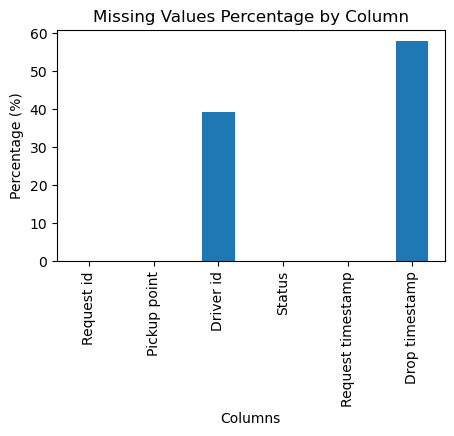

In [8]:
# Visualizing the missing values

# Missing Values Percentage
missing_percent = (df.isnull().sum() / len(df)) * 100

plt.figure(figsize=(5,3))
missing_percent.plot(kind='bar')
plt.title('Missing Values Percentage by Column')
plt.xlabel('Columns')
plt.ylabel('Percentage (%)')
plt.show()

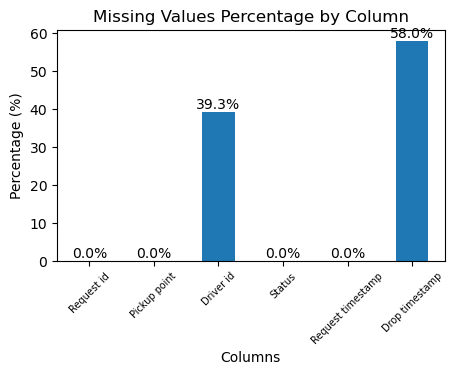

In [9]:
missing_percent = (df.isnull().sum() / len(df)) * 100

ax = missing_percent.plot(kind='bar', figsize=(5,3))

for i, v in enumerate(missing_percent):
    ax.text(i, v + 1, f'{v:.1f}%', ha='center')

plt.title('Missing Values Percentage by Column')
plt.xlabel('Columns')
plt.ylabel('Percentage (%)')
plt.xticks(rotation=45, fontsize=7)
plt.show()

In [10]:
# Check Unique Values for each variable.


for col in df.columns:
    print(f"\n{col}")
    print("Unique Values Count:", df[col].nunique())
    print(df[col].unique()[:10])  # first 10 unique values


Request id
Unique Values Count: 6745
[ 619  867 1807 2532 3112 3879 4270 5510 6248  267]

Pickup point
Unique Values Count: 2
['Airport' 'City']

Driver id
Unique Values Count: 300
[ 1.  2.  3.  4.  5.  6.  7.  8.  9. 10.]

Status
Unique Values Count: 3
['Trip Completed' 'Cancelled' 'No Cars Available']

Request timestamp
Unique Values Count: 5618
['11/7/2016 11:51' '11/7/2016 17:57' '12/7/2016 9:17' '12/7/2016 21:08'
 '13-07-2016 08:33:16' '13-07-2016 21:57:28' '14-07-2016 06:15:32'
 '15-07-2016 05:11:52' '15-07-2016 17:57:27' '11/7/2016 6:46']

Drop timestamp
Unique Values Count: 2598
['11/7/2016 13:00' '11/7/2016 18:47' '12/7/2016 9:58' '12/7/2016 22:03'
 '13-07-2016 09:25:47' '13-07-2016 22:28:59' '14-07-2016 07:13:15'
 '15-07-2016 06:07:52' '15-07-2016 18:50:51' '11/7/2016 7:25']


In [11]:
# Write your code to make your dataset analysis ready.
# Create a copy of dataset
df1 = df.copy()

# Check duplicate rows
print("Duplicate Rows:", df1.duplicated().sum())

# Convert timestamp columns into datetime format
df1['Request timestamp'] = pd.to_datetime(df1['Request timestamp'], errors='coerce')
df1['Drop timestamp'] = pd.to_datetime(df1['Drop timestamp'], errors='coerce')

# Create new time-based columns
df1['Request Hour'] = df1['Request timestamp'].dt.hour
df1['Request Day'] = df1['Request timestamp'].dt.day
df1['Request Month'] = df1['Request timestamp'].dt.month

# Check missing values
print("\nMissing Values:")
print(df1.isnull().sum())

# Dataset shape after wrangling
print("\nDataset Shape:", df1.shape)

# Display first 5 rows
df1.head()

Duplicate Rows: 0

Missing Values:
Request id              0
Pickup point            0
Driver id            2650
Status                  0
Request timestamp    4071
Drop timestamp       5595
Request Hour         4071
Request Day          4071
Request Month        4071
dtype: int64

Dataset Shape: (6745, 9)


,Request id,Pickup point,Driver id,Status,Request timestamp,Drop timestamp,Request Hour,Request Day,Request Month
0,619,Airport,1.0,Trip Completed,2016-11-07 11:51:00,2016-11-07 13:00:00,11.0,7.0,11.0
1,867,Airport,1.0,Trip Completed,2016-11-07 17:57:00,2016-11-07 18:47:00,17.0,7.0,11.0
2,1807,City,1.0,Trip Completed,2016-12-07 09:17:00,2016-12-07 09:58:00,9.0,7.0,12.0
3,2532,Airport,1.0,Trip Completed,2016-12-07 21:08:00,2016-12-07 22:03:00,21.0,7.0,12.0
4,3112,City,1.0,Trip Completed,NaT,NaT,NaN,NaN,NaN


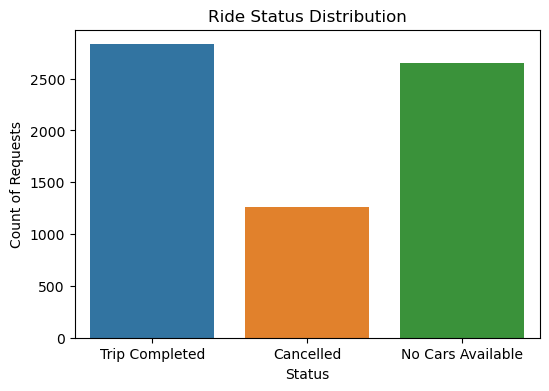

In [12]:
# Chart - 1 visualization code
#Chart 1: Ride Status Distribution (Bar Chart
plt.figure(figsize=(6,4))

sns.countplot(data=df, x='Status')

plt.title('Ride Status Distribution')
plt.xlabel('Status')
plt.ylabel('Count of Requests')

plt.show()

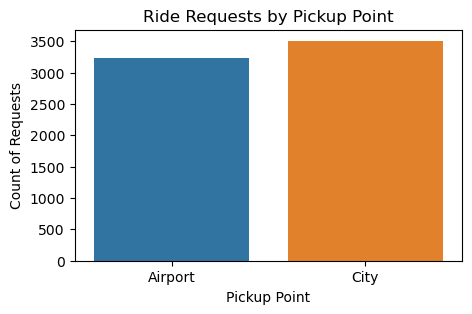

In [13]:
# Chart - 2 visualization code
plt.figure(figsize=(5,3))

sns.countplot(x='Pickup point', data=df)

plt.title('Ride Requests by Pickup Point')
plt.xlabel('Pickup Point')
plt.ylabel('Count of Requests')

plt.show()

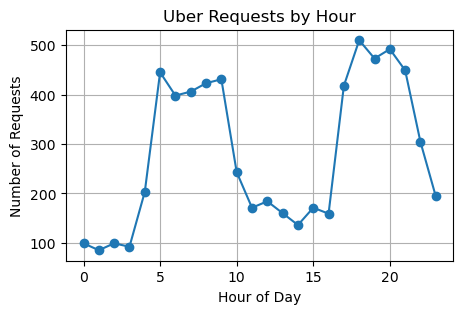

In [22]:
# Chart 3 - Requests by Hour

hourly_requests = df['Hour'].value_counts().sort_index()

plt.figure(figsize=(5,3))
plt.plot(hourly_requests.index,
         hourly_requests.values,
         marker='o')

plt.title('Uber Requests by Hour')
plt.xlabel('Hour of Day')
plt.ylabel('Number of Requests')
plt.grid(True)
plt.show()

In [20]:
print(df.columns)

Index(['Request id', 'Pickup point', 'Driver id', 'Status',
       'Request timestamp', 'Drop timestamp', 'Hour'],
      dtype='object')


In [16]:
import pandas as pd

df["Request timestamp"] = pd.to_datetime(df["Request timestamp"], format="mixed")
df["Drop timestamp"] = pd.to_datetime(df["Drop timestamp"], format="mixed")

In [19]:
df["Hour"] = df["Request timestamp"].dt.hour

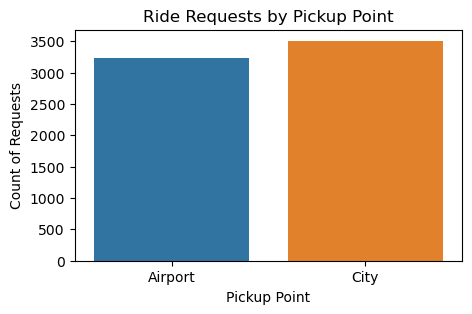

In [23]:
# Chart - 4 visualization code
plt.figure(figsize=(5,3))

sns.countplot(
    data=df,
    x='Pickup point'
)

plt.title('Ride Requests by Pickup Point')
plt.xlabel('Pickup Point')
plt.ylabel('Count of Requests')

plt.show()

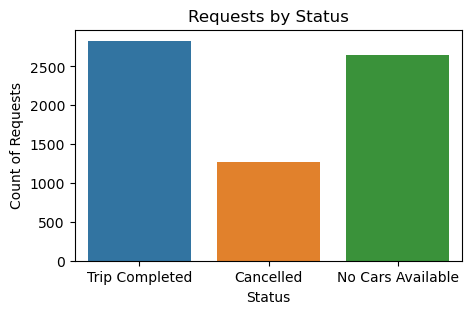

In [24]:
# Chart - 5 visualization code
# Chart - 5
plt.figure(figsize=(5,3))

sns.countplot(
    data=df,
    x='Status'
)

plt.title('Requests by Status')
plt.xlabel('Status')
plt.ylabel('Count of Requests')

plt.show()

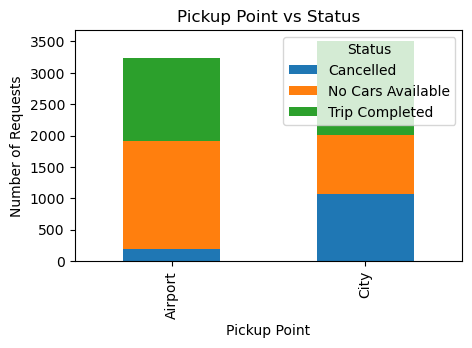

In [25]:
# Chart - 6 visualization code
pickup_status = pd.crosstab(
    df['Pickup point'],
    df['Status']
)

pickup_status.plot(
    kind='bar',
    stacked=True,
    figsize=(5,3)
)

plt.title('Pickup Point vs Status')
plt.xlabel('Pickup Point')
plt.ylabel('Number of Requests')
plt.legend(title='Status')
plt.show()

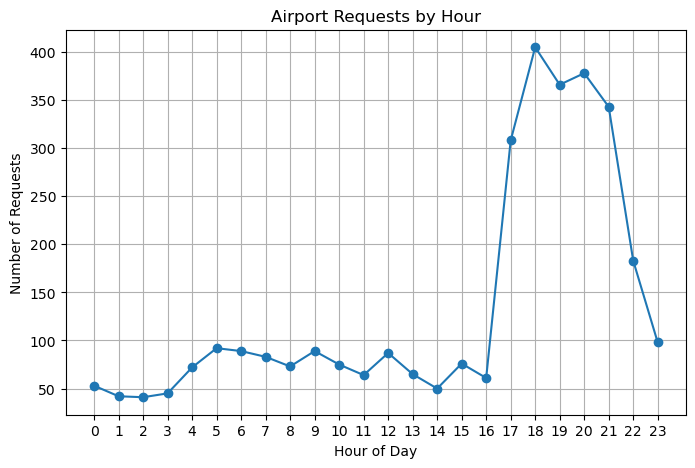

In [26]:
# Chart - 7 visualization code
# Chart - 7 : Airport Requests by Hour

airport_df = df[df['Pickup point'] == 'Airport']

airport_hourly = airport_df['Hour'].value_counts().sort_index()

plt.figure(figsize=(8,5))

plt.plot(
    airport_hourly.index,
    airport_hourly.values,
    marker='o'
)

plt.title('Airport Requests by Hour')
plt.xlabel('Hour of Day')
plt.ylabel('Number of Requests')
plt.xticks(range(0,24))
plt.grid(True)

plt.show()

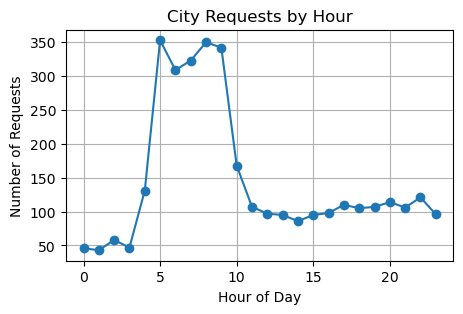

In [27]:
# Chart - 8 visualization code
city_data = df[df['Pickup point'] == 'City']

city_hourly = city_data['Hour'].value_counts().sort_index()

plt.figure(figsize=(5,3))

plt.plot(city_hourly.index,
         city_hourly.values,
         marker='o')

plt.title('City Requests by Hour')
plt.xlabel('Hour of Day')
plt.ylabel('Number of Requests')
plt.grid(True)

plt.show()


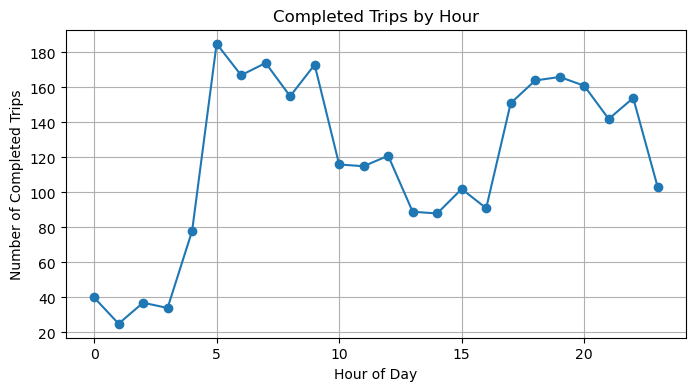

In [28]:
# Chart - 9 visualization code
# Chart 9 - Completed Trips by Hour

completed_trips = df[df['Status'] == 'Trip Completed']

completed_by_hour = completed_trips.groupby('Hour').size()

plt.figure(figsize=(8,4))
plt.plot(completed_by_hour.index,
         completed_by_hour.values,
         marker='o')

plt.title('Completed Trips by Hour')
plt.xlabel('Hour of Day')
plt.ylabel('Number of Completed Trips')
plt.grid(True)

plt.show()


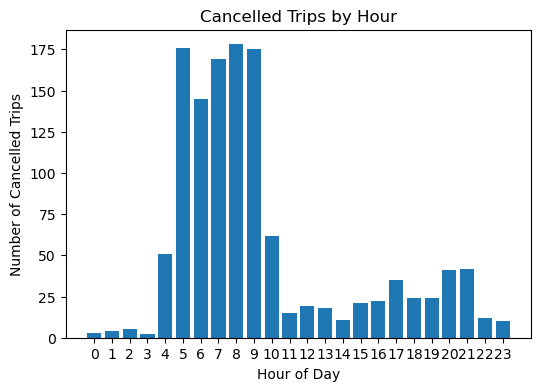

In [29]:
# Chart - 10 visualization code
# Chart - 10 : Cancelled Trips by Hour

cancelled = df[df['Status'] == 'Cancelled']

cancelled_by_hour = cancelled.groupby('Hour').size()

plt.figure(figsize=(6,4))

plt.bar(
    cancelled_by_hour.index,
    cancelled_by_hour.values
)

plt.title('Cancelled Trips by Hour')
plt.xlabel('Hour of Day')
plt.ylabel('Number of Cancelled Trips')

plt.xticks(range(24))
plt.show()


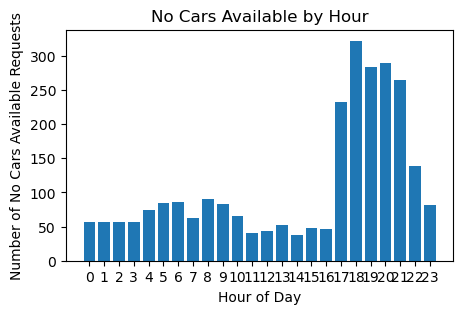

In [30]:
# Chart - 11 visualization code
# Chart 11 - No Cars Available by Hour

no_cars = df[df['Status'] == 'No Cars Available']

hourly_no_cars = no_cars.groupby('Hour').size()

plt.figure(figsize=(5,3))

plt.bar(hourly_no_cars.index,
        hourly_no_cars.values)

plt.title('No Cars Available by Hour')
plt.xlabel('Hour of Day')
plt.ylabel('Number of No Cars Available Requests')
plt.xticks(range(24))

plt.show()

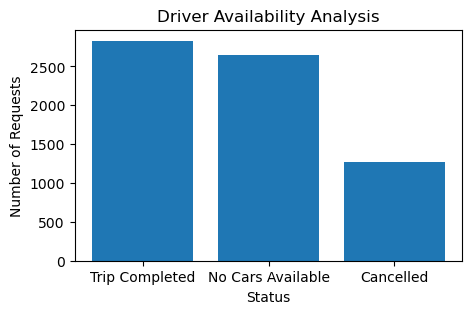

In [31]:
# Chart - 12 visualization
# Chart 12 - Driver Availability Analysis

driver_availability = df['Status'].value_counts()

plt.figure(figsize=(5,3))

plt.bar(driver_availability.index,
        driver_availability.values)

plt.title('Driver Availability Analysis')
plt.xlabel('Status')
plt.ylabel('Number of Requests')

plt.show()

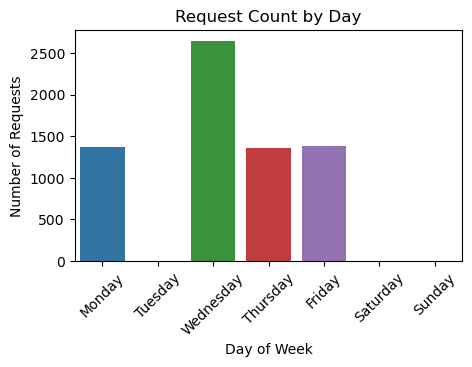

In [32]:
# Chart - 13 visualization code
# Chart 13 - Request Count by Day

df['Request timestamp'] = pd.to_datetime(
    df['Request timestamp'],
    format='%d-%m-%Y %H:%M',
    errors='coerce'
)

df['Day'] = df['Request timestamp'].dt.day_name()

day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday',
             'Friday', 'Saturday', 'Sunday']

daily_requests = df['Day'].value_counts().reindex(day_order)

plt.figure(figsize=(5,3))

sns.barplot(
    x=daily_requests.index,
    y=daily_requests.values
)

plt.title('Request Count by Day')
plt.xlabel('Day of Week')
plt.ylabel('Number of Requests')
plt.xticks(rotation=45)

plt.show()

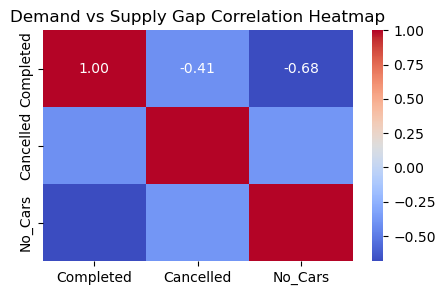

In [33]:
# Correlation Heatmap visualization code
import seaborn as sns
import matplotlib.pyplot as plt

df['Completed'] = (df['Status'] == 'Trip Completed').astype(int)
df['Cancelled'] = (df['Status'] == 'Cancelled').astype(int)
df['No_Cars'] = (df['Status'] == 'No Cars Available').astype(int)

corr_data = df[['Completed', 'Cancelled', 'No_Cars']].corr()

plt.figure(figsize=(5,3))
sns.heatmap(corr_data,
            annot=True,
            cmap='coolwarm',
            fmt='.2f')

plt.title('Demand vs Supply Gap Correlation Heatmap')
plt.show()


C:\Users\Prasanna Kumar\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\Prasanna Kumar\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\Prasanna Kumar\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\Prasanna Kumar\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Conver

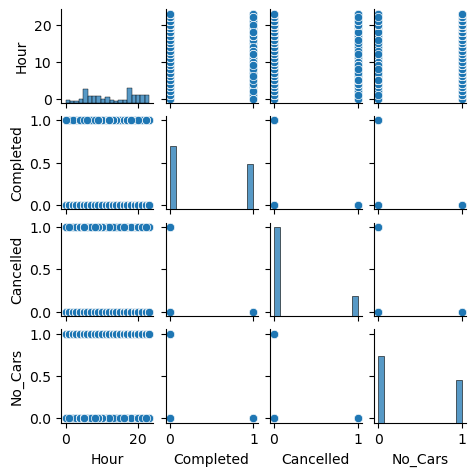

In [34]:
# Pair Plot visualization code
import seaborn as sns
import matplotlib.pyplot as plt

pair_df = df[['Hour', 'Completed', 'Cancelled', 'No_Cars']]

sns.pairplot(
    pair_df,
    height=1.2  # size chhota karne ke liye
)

plt.show()


In [36]:
'''
Conclusion

The analysis of the Uber Request Dataset revealed a significant demand-supply gap during peak hours. Morning hours experienced a high number of trip cancellations, while evening hours showed a large number of "No Cars Available" requests, especially at the airport.

The findings indicate that driver availability is not sufficient during high-demand periods. By improving driver allocation, offering incentives during peak hours, and using demand forecasting, Uber can reduce cancellations, increase trip completion rates, improve customer satisfaction, and generate higher revenue.

Overall, the analysis successfully identified key operational challenges and provided actionable recommendations to improve Uber's service efficiency and business performance.'''

'\nConclusion\n\nThe analysis of the Uber Request Dataset revealed a significant demand-supply gap during peak hours. Morning hours experienced a high number of trip cancellations, while evening hours showed a large number of "No Cars Available" requests, especially at the airport.\n\nThe findings indicate that driver availability is not sufficient during high-demand periods. By improving driver allocation, offering incentives during peak hours, and using demand forecasting, Uber can reduce cancellations, increase trip completion rates, improve customer satisfaction, and generate higher revenue.\n\nOverall, the analysis successfully identified key operational challenges and provided actionable recommendations to improve Uber\'s service efficiency and business performance.'

In [37]:
df.to_csv("Uber_Request_Data_Clean.csv", index=False, na_rep="")